<a href="https://colab.research.google.com/github/S-J-I/Seth_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
#Please write the code here

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

data = pd.read_csv('car_purchase_data.csv')
display(data.head())
print('Shape:', data.shape)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Shape: (400, 5)


### Step 2: Split features and target

In [4]:
#Please write the code here

X = data[['Age', 'Salary']]
y = data['Purchased']

print('X Shape:', X.shape, 'Y Shape:', y.shape)
print('Y Distribution:', y.value_counts())


X Shape: (400, 2) Y Shape: (400,)
Y Distribution: Purchased
0    257
1    143
Name: count, dtype: int64


### Step 3: Train/Test Split

In [15]:
#Please write the code here

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)

print('Train Size:', x_train.shape[0], 'Test Size:', x_test.shape[0])

Train Size: 320 Test Size: 80


### Step 4: Feature Scaling

In [16]:
#Please write the code here

Scaler = StandardScaler()
x_train = Scaler.fit_transform(x_train)
x_test = Scaler.transform(x_test)
print('Scaling Complete')

Scaling Complete


### Step 5: Train Logistic Regression Model

In [18]:
#Please write the code here

Model = LogisticRegression(max_iter=1000)
Model.fit(x_train, y_train)

print('Model Trained')

Model Trained


### Step 6: Predict and Evaluate

In [20]:
#Please write the code here

y_pred = Model.predict(x_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print('Accuracy:', acc)
print('Confusion Matrix:\n', cm)
print('Classification Reprot:', classification_report(y_test, y_pred))

Accuracy: 0.8125
Confusion Matrix:
 [[47  4]
 [11 18]]
Classification Reprot:               precision    recall  f1-score   support

           0       0.81      0.92      0.86        51
           1       0.82      0.62      0.71        29

    accuracy                           0.81        80
   macro avg       0.81      0.77      0.78        80
weighted avg       0.81      0.81      0.81        80



### Step 7: Visualization of Decision Regions

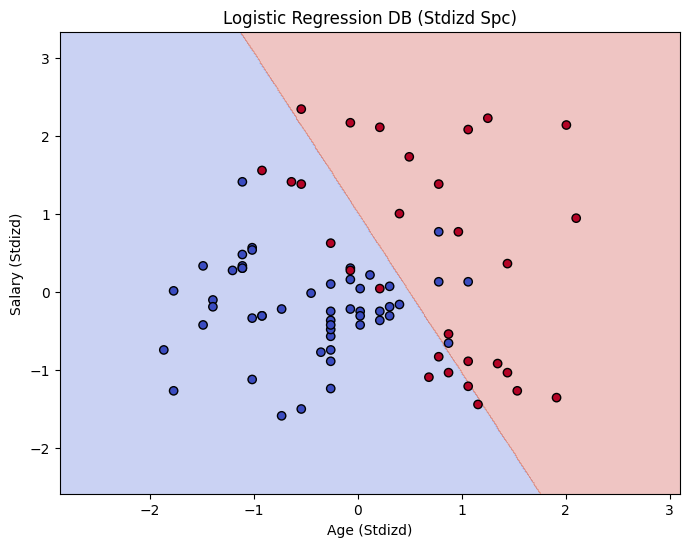

In [22]:
#Please write the code here


import numpy as np
import matplotlib.pyplot as plt

X_set, y_set = x_test[:, :2], y_test.values
model_2d = LogisticRegression(max_iter=1000)
model_2d.fit(x_train[:, :2], y_train)

X1_min, X1_max = X_set[:, 0].min() - 1, X_set[:, 0].max() + 1
X2_min, X2_max = X_set[:, 1].min() - 1, X_set[:, 1].max() + 1
X1, X2 = np.meshgrid(np.arange(start=X1_min, stop=X1_max, step=0.01), np.arange(start=X2_min, stop=X2_max, step=0.01))

Z = model_2d.predict(np.array([X1.ravel(), X2.ravel()]).T)
Z = Z.reshape(X1.shape)

plt.figure(figsize=(8,6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_set[:, 0], X_set[:, 1], c=y_set, edgecolor='k', cmap='coolwarm')
plt.title('Logistic Regression DB (Stdizd Spc)')
plt.xlabel('Age (Stdizd)')
plt.ylabel('Salary (Stdizd)')
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

It can be used for classification because it takes a probability & shifts it into a category. It also reflects a binary outcome which is either buying a car or not. In this case it takes probability of a car being purchased >= 50% as a purchase.

Older customers with a higher salary are more likely.

Being limited to age & salary as the only factors probably hurts it a bit. The model predicted 15 customers incorrectly & 11 actually bought a car so there's some misses.

Whether they're employed to begin with & previous car history would be ideal. Different training & test splits could see if the model's consistent.